# Esquema de memoria: perfil

## Repaso

Presentamos el [Store de memoria de LangGraph](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore) como una forma de guardar y recuperar memorias a largo plazo.

Construimos un chatbot simple que usa memoria `a corto plazo (dentro del hilo)` y memoria `a largo plazo (entre hilos)`.

Guardó memoria semántica a largo plazo ([hechos sobre el usuario](https://docs.langchain.com/oss/python/concepts/memory#semantic-memory)) ["en la ruta crítica"](https://docs.langchain.com/oss/python/concepts/memory#writing-memories) (*hot path*), mientras el usuario conversaba con él.

## Objetivos

Nuestro chatbot guardaba las memorias como un string. En la práctica, muchas veces queremos que las memorias tengan estructura.

Por ejemplo, las memorias pueden ser un [único esquema que se actualiza de forma continua](https://docs.langchain.com/oss/python/concepts/memory#profile).

En nuestro caso, queremos que sea un único perfil de usuario.

Ampliaremos nuestro chatbot para que guarde memorias semánticas en un único [perfil de usuario](https://docs.langchain.com/oss/python/concepts/memory#profile).

También presentaremos una biblioteca, [Trustcall](https://github.com/hinthornw/trustcall), para actualizar este esquema con información nueva.

In [7]:
%%capture --no-stderr
%pip install -U langchain_openai langgraph trustcall langchain_core

In [1]:
import os, getpass

def _definir_variable(variable: str):
    # Revisamos si la variable está definida en el entorno del sistema operativo
    valor_entorno = os.environ.get(variable)
    if not valor_entorno:
        # Si no está definida, se la pedimos al usuario
        valor_entorno = getpass.getpass(f"{variable}: ")

    # Definimos la variable de entorno para el proceso actual
    os.environ[variable] = valor_entorno

_definir_variable("LANGSMITH_API_KEY")
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "langchain-academy"

## Definir un esquema de perfil de usuario

Python tiene muchos tipos para [datos estructurados](https://docs.langchain.com/oss/python/langchain/models#structured-outputs), como TypedDict, diccionarios, JSON y [Pydantic](https://docs.pydantic.dev/latest/).

Empecemos usando TypedDict para definir un esquema de perfil de usuario.

In [3]:
from typing import TypedDict, List

class PerfilUsuario(TypedDict):
    """Esquema de perfil de usuario con campos tipados"""
    nombre_usuario: str  # El nombre preferido del usuario
    intereses: List[str]  # Una lista con los intereses del usuario

## Guardar un esquema en el Store

El [Store de LangGraph](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore) acepta cualquier diccionario de Python como `value`.

In [4]:
# Instancia del TypedDict
perfil_usuario: PerfilUsuario = {
    "nombre_usuario": "Lance",
    "intereses": ["andar en bicicleta", "tecnología", "café"]
}
perfil_usuario

{'user_name': 'Lance', 'interests': ['biking', 'technology', 'coffee']}

Usamos el método [put](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore.put) para guardar el TypedDict en el Store.

In [5]:
import uuid
from langgraph.store.memory import InMemoryStore

# Inicializamos el Store en memoria
store_en_memoria = InMemoryStore()

# Namespace de la memoria que vamos a guardar
id_usuario = "1"
namespace_para_memoria = (id_usuario, "memoria")

# Guardamos una memoria en el namespace con una clave y un valor
clave = "perfil_usuario"
valor = perfil_usuario
store_en_memoria.put(namespace_para_memoria, clave, valor)

Usamos [search](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore.search) para recuperar objetos del Store según su namespace.

In [6]:
# Búsqueda
for m in store_en_memoria.search(namespace_para_memoria):
    print(m.dict())

{'value': {'user_name': 'Lance', 'interests': ['biking', 'technology', 'coffee']}, 'key': 'user_profile', 'namespace': ['1', 'memory'], 'created_at': '2024-11-04T23:37:34.871675+00:00', 'updated_at': '2024-11-04T23:37:34.871680+00:00'}


También podemos usar [get](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore.get) para recuperar un objeto concreto por su namespace y su clave.

In [7]:
# Obtenemos la memoria por namespace y clave
perfil = store_en_memoria.get(namespace_para_memoria, "perfil_usuario")
perfil.value

{'user_name': 'Lance', 'interests': ['biking', 'technology', 'coffee']}

## Chatbot con esquema de perfil

Ahora sabemos cómo especificar un esquema para las memorias y guardarlo en el Store.

Pero, ¿cómo *creamos* de verdad memorias con este esquema en particular?

En nuestro chatbot, [queremos crear memorias a partir de la conversación con el usuario](https://docs.langchain.com/oss/python/concepts/memory#profile).

Aquí es útil el concepto de [salidas estructuradas](https://docs.langchain.com/oss/python/langchain/models#structured-outputs) (*structured outputs*).

La interfaz de [modelo de chat](https://docs.langchain.com/oss/python/langchain/models) de LangChain tiene un método [`with_structured_output`](https://docs.langchain.com/oss/python/langchain/models#structured-outputs) para forzar una salida estructurada.

Es útil cuando queremos garantizar que la salida cumpla un esquema, y además nos parsea la salida.

In [7]:
_definir_variable("OPENAI_API_KEY")

Pasemos el esquema `PerfilUsuario` que creamos al método `with_structured_output`.

Luego podemos invocar el modelo de chat con una lista de [mensajes](https://docs.langchain.com/oss/python/langchain/messages) y obtener una salida estructurada que cumple nuestro esquema.

In [8]:
from pydantic import BaseModel, Field

from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

# Inicializamos el modelo
modelo = ChatOpenAI(model="gpt-4o", temperature=0)

# Vinculamos el esquema al modelo
modelo_con_estructura = modelo.with_structured_output(PerfilUsuario)

# Invocamos el modelo para producir una salida estructurada que coincida con el esquema
salida_estructurada = modelo_con_estructura.invoke([HumanMessage("Me llamo Lance y me gusta andar en bicicleta.")])
salida_estructurada

{'user_name': 'Lance', 'interests': ['biking']}

Ahora usemos esto con nuestro chatbot.

Solo requiere cambios menores en la función `escribir_memoria`.

Usamos `modelo_con_estructura`, definido arriba, para producir un perfil que coincida con nuestro esquema.

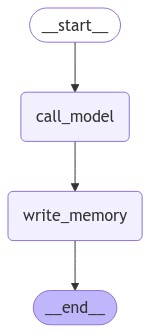

In [9]:
from IPython.display import Image, display

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.store.base import BaseStore

from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_core.runnables.config import RunnableConfig

# Instrucción del chatbot
MENSAJE_SISTEMA_MODELO = """Eres un asistente útil con memoria que entrega información sobre el usuario.
Si tienes memoria de este usuario, úsala para personalizar tus respuestas.
Esta es la memoria (puede estar vacía): {memoria}"""

# Crear una memoria nueva a partir del historial del chat y de la memoria existente, si la hay
INSTRUCCION_CREAR_MEMORIA = """Crea o actualiza una memoria de perfil de usuario a partir del historial del chat del usuario.
Se guardará como memoria a largo plazo. Si ya existe una memoria, simplemente actualízala.
Esta es la memoria existente (puede estar vacía): {memoria}"""

def llamar_modelo(estado: MessagesState, config: RunnableConfig, store: BaseStore):

    """Carga la memoria desde el Store y la usa para personalizar la respuesta del chatbot."""

    # Obtenemos el id del usuario desde la configuración
    id_usuario = config["configurable"]["id_usuario"]

    # Recuperamos la memoria desde el Store
    namespace = ("memoria", id_usuario)
    memoria_existente = store.get(namespace, "memoria_usuario")

    # Damos formato a las memorias para el mensaje de sistema
    if memoria_existente and memoria_existente.value:
        dict_memoria = memoria_existente.value
        memoria_formateada = (
            f"Nombre: {dict_memoria.get('nombre_usuario', 'Desconocido')}\n"
            f"Intereses: {', '.join(dict_memoria.get('intereses', []))}"
        )
    else:
        memoria_formateada = None

    # Damos formato a la memoria dentro del mensaje de sistema
    mensaje_sistema = MENSAJE_SISTEMA_MODELO.format(memoria=memoria_formateada)

    # Respondemos usando la memoria y el historial del chat
    respuesta = modelo.invoke([SystemMessage(content=mensaje_sistema)]+estado["messages"])

    return {"messages": respuesta}

def escribir_memoria(estado: MessagesState, config: RunnableConfig, store: BaseStore):

    """Reflexiona sobre el historial del chat y guarda una memoria en el Store."""

    # Obtenemos el id del usuario desde la configuración
    id_usuario = config["configurable"]["id_usuario"]

    # Recuperamos la memoria existente desde el Store
    namespace = ("memoria", id_usuario)
    memoria_existente = store.get(namespace, "memoria_usuario")

    # Damos formato a las memorias para el mensaje de sistema
    if memoria_existente and memoria_existente.value:
        dict_memoria = memoria_existente.value
        memoria_formateada = (
            f"Nombre: {dict_memoria.get('nombre_usuario', 'Desconocido')}\n"
            f"Intereses: {', '.join(dict_memoria.get('intereses', []))}"
        )
    else:
        memoria_formateada = None

    # Damos formato a la memoria existente dentro de la instrucción
    mensaje_sistema = INSTRUCCION_CREAR_MEMORIA.format(memoria=memoria_formateada)

    # Invocamos el modelo para producir una salida estructurada que coincida con el esquema
    memoria_nueva = modelo_con_estructura.invoke([SystemMessage(content=mensaje_sistema)]+estado['messages'])

    # Sobrescribimos la memoria de perfil de usuario existente
    clave = "memoria_usuario"
    store.put(namespace, clave, memoria_nueva)

# Definimos el grafo
constructor = StateGraph(MessagesState)
constructor.add_node("llamar_modelo", llamar_modelo)
constructor.add_node("escribir_memoria", escribir_memoria)
constructor.add_edge(START, "llamar_modelo")
constructor.add_edge("llamar_modelo", "escribir_memoria")
constructor.add_edge("escribir_memoria", END)

# Store para la memoria a largo plazo (entre hilos)
memoria_entre_hilos = InMemoryStore()

# Checkpointer para la memoria a corto plazo (dentro del hilo)
memoria_del_hilo = MemorySaver()

# Compilamos el grafo con el checkpointer y el Store
grafo = constructor.compile(checkpointer=memoria_del_hilo, store=memoria_entre_hilos)

# Visualización
display(Image(grafo.get_graph(xray=1).draw_mermaid_png()))

In [10]:
# Entregamos un id de hilo para la memoria a corto plazo (dentro del hilo)
# Entregamos un id de usuario para la memoria a largo plazo (entre hilos)
config = {"configurable": {"thread_id": "1", "id_usuario": "1"}}

# Entrada del usuario
mensajes_entrada = [HumanMessage(content="Hola, me llamo Lance y me gusta andar en bicicleta por San Francisco y comer en panaderías.")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

Hi, my name is Lance and I like to bike around San Francisco and eat at bakeries.
================================== Ai Message ==================================

Hi Lance! It's great to meet you. Biking around San Francisco sounds like a fantastic way to explore the city, and there are so many amazing bakeries to try. Do you have any favorite bakeries or biking routes in the city?


Revisemos la memoria en el Store.

Vemos que la memoria es un diccionario que coincide con nuestro esquema.

In [11]:
# Namespace de la memoria que vamos a guardar
id_usuario = "1"
namespace = ("memoria", id_usuario)
memoria_existente = memoria_entre_hilos.get(namespace, "memoria_usuario")
memoria_existente.value

{'user_name': 'Lance', 'interests': ['biking', 'bakeries', 'San Francisco']}

## ¿Cuándo puede fallar?

[`with_structured_output`](https://docs.langchain.com/oss/python/langchain/models#structured-outputs) es muy útil, pero ¿qué pasa si trabajamos con un esquema más complejo?

[Aquí](https://github.com/hinthornw/trustcall?tab=readme-ov-file#complex-schema) hay un ejemplo de un esquema más complejo, que probaremos a continuación.

Es un modelo de [Pydantic](https://docs.pydantic.dev/latest/) que describe las preferencias de un usuario sobre comunicación y sobre la caída de confianza (*trust fall*).

In [18]:
from typing import List, Optional

class FormatoSalida(BaseModel):
    preferencia: str
    frase_preferencia_revelada: str

class PreferenciasTelegrama(BaseModel):
    codificacion_preferida: Optional[List[FormatoSalida]] = None
    operadores_telegrama_favoritos: Optional[List[FormatoSalida]] = None
    papel_telegrama_preferido: Optional[List[FormatoSalida]] = None

class CodigoMorse(BaseModel):
    tipo_llave_preferido: Optional[List[FormatoSalida]] = None
    abreviaturas_morse_favoritas: Optional[List[FormatoSalida]] = None

class Semaforo(BaseModel):
    color_bandera_preferido: Optional[List[FormatoSalida]] = None
    nivel_habilidad_semaforo: Optional[List[FormatoSalida]] = None

class PreferenciasCaidaConfianza(BaseModel):
    altura_caida_preferida: Optional[List[FormatoSalida]] = None
    nivel_confianza: Optional[List[FormatoSalida]] = None
    tecnica_atrapada_preferida: Optional[List[FormatoSalida]] = None

class PreferenciasComunicacion(BaseModel):
    telegrama: PreferenciasTelegrama
    codigo_morse: CodigoMorse
    semaforo: Semaforo

class PreferenciasUsuario(BaseModel):
    preferencias_comunicacion: PreferenciasComunicacion
    preferencias_caida_confianza: PreferenciasCaidaConfianza

class PreferenciasTelegramaYCaidaConfianza(BaseModel):
    preferencias_usuario_pertinentes: PreferenciasUsuario

Ahora intentemos extraer este esquema con el método `with_structured_output`.

In [19]:
from pydantic import ValidationError

# Vinculamos el esquema al modelo
modelo_con_estructura = modelo.with_structured_output(PreferenciasTelegramaYCaidaConfianza)

# Conversación
conversacion = """Operador: ¿En qué puedo ayudarle con su telegrama, señor?
Cliente: Necesito enviar un mensaje sobre nuestro ejercicio de caída de confianza.
Operador: Por supuesto. ¿Código Morse o codificación estándar?
Cliente: Morse, por favor. Me encanta usar una llave recta.
Operador: Excelente. ¿Cuál es su mensaje?
Cliente: Dígale que estoy listo para una caída más alta, y que prefiero la formación en diamante para atrapar.
Operador: Listo. ¿Uso nuestro papel "Temerario" para este mensaje tan audaz?
Cliente: ¡Perfecto! Envíelo con su paloma mensajera más veloz.
Operador: Llegará dentro de la hora, señor."""

# Invocamos el modelo
try:
    modelo_con_estructura.invoke(f"""Extrae las preferencias de la siguiente conversación:
    <convo>
    {conversacion}
    </convo>""")
except ValidationError as e:
    print(e)

1 validation error for TelegramAndTrustFallPreferences
pertinent_user_preferences.communication_preferences.semaphore
  Input should be a valid dictionary or instance of Semaphore [type=model_type, input_value=None, input_type=NoneType]
    For further information visit https://errors.pydantic.dev/2.9/v/model_type


Si extraemos esquemas más complejos de forma ingenua, incluso con un modelo de alta capacidad como `gpt-4o`, es propenso a fallar.

## Trustcall para crear y actualizar esquemas de perfil

Como vemos, trabajar con esquemas puede ser difícil.

Los esquemas complejos son difíciles de extraer.

Además, actualizar incluso esquemas simples puede traer problemas.

Pensemos en nuestro chatbot anterior.

Cada vez que decidíamos guardar una memoria nueva, regenerábamos el esquema del perfil *desde cero*.

Eso es ineficiente: si el esquema contiene mucha información, se gastan tokens del modelo en volver a generarla cada vez.

Peor aún, podemos perder información al regenerar el perfil desde cero.

¡Resolver estos problemas es la motivación de [TrustCall](https://github.com/hinthornw/trustcall)!

Es una biblioteca de código abierto para actualizar esquemas JSON, desarrollada por [Will Fu-Hinthorn](https://github.com/hinthornw), del equipo de LangChain.

Nació justamente de estos desafíos al trabajar con memoria.

Primero veamos un uso simple de la extracción con TrustCall sobre esta lista de [mensajes](https://docs.langchain.com/oss/python/langchain/messages).

In [20]:
# Conversación
conversacion = [HumanMessage(content="Hola, soy Lance."),
                AIMessage(content="Mucho gusto, Lance."),
                HumanMessage(content="Me gusta mucho andar en bicicleta por San Francisco.")]

Usamos `create_extractor`, pasándole el modelo y nuestro esquema como una [herramienta](https://docs.langchain.com/oss/python/langchain/tools).

Con TrustCall podemos entregar el esquema de varias formas.

Por ejemplo, podemos pasar un objeto JSON / diccionario de Python o un modelo de Pydantic.

Por debajo, TrustCall usa [llamadas a herramientas](https://docs.langchain.com/oss/python/langchain/models#tool-calling) (*tool calling*) para producir una [salida estructurada](https://docs.langchain.com/oss/python/langchain/models#structured-outputs) a partir de una lista de [mensajes](https://docs.langchain.com/oss/python/langchain/messages) de entrada.

Para obligar a Trustcall a producir una salida estructurada, podemos incluir el nombre del esquema en el argumento `tool_choice`.

Podemos invocar el extractor con la conversación anterior.

In [21]:
from trustcall import create_extractor

# Esquema
class PerfilUsuario(BaseModel):
    """Esquema de perfil de usuario con campos tipados"""
    nombre_usuario: str = Field(description="El nombre preferido del usuario")
    intereses: List[str] = Field(description="Una lista con los intereses del usuario")

# Inicializamos el modelo
modelo = ChatOpenAI(model="gpt-4o", temperature=0)

# Creamos el extractor
extractor_trustcall = create_extractor(
    modelo,
    tools=[PerfilUsuario],
    tool_choice="PerfilUsuario"
)

# Instrucción
mensaje_sistema = "Extrae el perfil del usuario de la siguiente conversación"

# Invocamos el extractor
resultado = extractor_trustcall.invoke({"messages": [SystemMessage(content=mensaje_sistema)]+conversacion})

Cuando invocamos el extractor, obtenemos varias cosas:

* `messages`: la lista de `AIMessages` que contienen las llamadas a herramientas.
* `responses`: las llamadas a herramientas ya parseadas que coinciden con nuestro esquema.
* `response_metadata`: se aplica si estamos actualizando objetos existentes. Indica cuál de las respuestas corresponde a cuál de los objetos existentes.

In [17]:
for m in resultado["messages"]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  UserProfile (call_spGGUsoaUFXU7oOrUNCASzfL)
 Call ID: call_spGGUsoaUFXU7oOrUNCASzfL
  Args:
    user_name: Lance
    interests: ['biking around San Francisco']


In [18]:
esquema = resultado["responses"]
esquema

[UserProfile(user_name='Lance', interests=['biking around San Francisco'])]

In [19]:
esquema[0].model_dump()

{'user_name': 'Lance', 'interests': ['biking around San Francisco']}

In [20]:
resultado["response_metadata"]

[{'id': 'call_spGGUsoaUFXU7oOrUNCASzfL'}]

Veamos cómo usarlo para *actualizar* el perfil.

Para actualizar, TrustCall recibe un conjunto de mensajes y el esquema existente.

La idea central es que le pide al modelo producir un [JSON Patch](https://jsonpatch.com/) para actualizar solo las partes relevantes del esquema.

Esto es menos propenso a errores que sobrescribir de forma ingenua el esquema completo.

También es más eficiente, porque el modelo solo necesita generar las partes del esquema que cambiaron.

Podemos guardar el esquema existente como un diccionario.

Podemos usar `model_dump()` para serializar una instancia de un modelo de Pydantic en un diccionario.

Se lo pasamos al argumento `"existing"` junto con el nombre del esquema, `PerfilUsuario`.

In [21]:
# Actualizamos la conversación
conversacion_actualizada = [HumanMessage(content="Hola, soy Lance."),
                            AIMessage(content="Mucho gusto, Lance."),
                            HumanMessage(content="Me gusta mucho andar en bicicleta por San Francisco."),
                            AIMessage(content="¡San Francisco es una gran ciudad! ¿Adónde vas después de andar en bicicleta?"),
                            HumanMessage(content="Después de andar en bicicleta me gusta mucho ir a una panadería."),]

# Actualizamos la instrucción
mensaje_sistema = f"""Actualiza la memoria (documento JSON) para incorporar la información nueva de la siguiente conversación"""

# Invocamos el extractor con la instrucción actualizada y el perfil existente, junto con el nombre de la herramienta correspondiente (PerfilUsuario)
resultado = extractor_trustcall.invoke({"messages": [SystemMessage(content=mensaje_sistema)]+conversacion_actualizada},
                                    {"existing": {"PerfilUsuario": esquema[0].model_dump()}})

In [22]:
for m in resultado["messages"]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  UserProfile (call_WeZl0ACfQStxblim0ps8LNKT)
 Call ID: call_WeZl0ACfQStxblim0ps8LNKT
  Args:
    user_name: Lance
    interests: ['biking', 'visiting bakeries']


In [23]:
resultado["response_metadata"]

[{'id': 'call_WeZl0ACfQStxblim0ps8LNKT'}]

In [24]:
esquema_actualizado = resultado["responses"][0]
esquema_actualizado.model_dump()

{'user_name': 'Lance', 'interests': ['biking', 'visiting bakeries']}

Traza de LangSmith:

https://smith.langchain.com/public/229eae22-1edb-44c6-93e6-489124a43968/r

Ahora probemos también Trustcall con el [esquema difícil](https://github.com/hinthornw/trustcall?tab=readme-ov-file#complex-schema) que vimos antes.

In [25]:
extractor = create_extractor(
    modelo,
    tools=[PreferenciasTelegramaYCaidaConfianza],
    tool_choice="PreferenciasTelegramaYCaidaConfianza",
)

# Conversación
conversacion = """Operador: ¿En qué puedo ayudarle con su telegrama, señor?
Cliente: Necesito enviar un mensaje sobre nuestro ejercicio de caída de confianza.
Operador: Por supuesto. ¿Código Morse o codificación estándar?
Cliente: Morse, por favor. Me encanta usar una llave recta.
Operador: Excelente. ¿Cuál es su mensaje?
Cliente: Dígale que estoy listo para una caída más alta, y que prefiero la formación en diamante para atrapar.
Operador: Listo. ¿Uso nuestro papel "Temerario" para este mensaje tan audaz?
Cliente: ¡Perfecto! Envíelo con su paloma mensajera más veloz.
Operador: Llegará dentro de la hora, señor."""

resultado = extractor.invoke(
    f"""Extrae las preferencias de la siguiente conversación:
<convo>
{conversacion}
</convo>"""
)

# Extraemos las preferencias
resultado["responses"][0]

TelegramAndTrustFallPreferences(pertinent_user_preferences=UserPreferences(communication_preferences=CommunicationPreferences(telegram=TelegramPreferences(preferred_encoding=[OutputFormat(preference='standard encoding', sentence_preference_revealed='standard encoding')], favorite_telegram_operators=None, preferred_telegram_paper=[OutputFormat(preference='Daredevil', sentence_preference_revealed='Daredevil')]), morse_code=MorseCode(preferred_key_type=[OutputFormat(preference='straight key', sentence_preference_revealed='straight key')], favorite_morse_abbreviations=None), semaphore=Semaphore(preferred_flag_color=None, semaphore_skill_level=None)), trust_fall_preferences=TrustFallPreferences(preferred_fall_height=[OutputFormat(preference='higher', sentence_preference_revealed='higher')], trust_level=None, preferred_catching_technique=[OutputFormat(preference='diamond formation', sentence_preference_revealed='diamond formation')])))

Traza:

https://smith.langchain.com/public/5cd23009-3e05-4b00-99f0-c66ee3edd06e/r

Para ver más ejemplos, puedes mirar un video de resumen [aquí](https://www.youtube.com/watch?v=-H4s0jQi-QY).

## Chatbot con actualización del esquema de perfil

Ahora incorporemos Trustcall a nuestro chatbot para crear *y actualizar* un perfil de memoria.

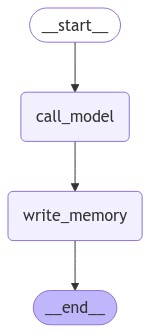

In [22]:
from IPython.display import Image, display

from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_core.runnables.config import RunnableConfig
from langgraph.checkpoint.memory import MemorySaver
from langgraph.store.base import BaseStore

# Inicializamos el modelo
modelo = ChatOpenAI(model="gpt-4o", temperature=0)

# Esquema
class PerfilUsuario(BaseModel):
    """ Perfil de un usuario """
    nombre_usuario: str = Field(description="El nombre preferido del usuario")
    ubicacion_usuario: str = Field(description="La ubicación del usuario")
    intereses: list = Field(description="Una lista con los intereses del usuario")

# Creamos el extractor
extractor_trustcall = create_extractor(
    modelo,
    tools=[PerfilUsuario],
    tool_choice="PerfilUsuario", # Obliga a usar la herramienta PerfilUsuario
)

# Instrucción del chatbot
MENSAJE_SISTEMA_MODELO = """Eres un asistente útil con memoria que entrega información sobre el usuario.
Si tienes memoria de este usuario, úsala para personalizar tus respuestas.
Esta es la memoria (puede estar vacía): {memoria}"""

# Instrucción de extracción
INSTRUCCION_TRUSTCALL = """Crea o actualiza la memoria (documento JSON) para incorporar la información de la siguiente conversación:"""

def llamar_modelo(estado: MessagesState, config: RunnableConfig, store: BaseStore):

    """Carga la memoria desde el Store y la usa para personalizar la respuesta del chatbot."""

    # Obtenemos el id del usuario desde la configuración
    id_usuario = config["configurable"]["id_usuario"]

    # Recuperamos la memoria desde el Store
    namespace = ("memoria", id_usuario)
    memoria_existente = store.get(namespace, "memoria_usuario")

    # Damos formato a las memorias para el mensaje de sistema
    if memoria_existente and memoria_existente.value:
        dict_memoria = memoria_existente.value
        memoria_formateada = (
            f"Nombre: {dict_memoria.get('nombre_usuario', 'Desconocido')}\n"
            f"Ubicación: {dict_memoria.get('ubicacion_usuario', 'Desconocida')}\n"
            f"Intereses: {', '.join(dict_memoria.get('intereses', []))}"
        )
    else:
        memoria_formateada = None

    # Damos formato a la memoria dentro del mensaje de sistema
    mensaje_sistema = MENSAJE_SISTEMA_MODELO.format(memoria=memoria_formateada)

    # Respondemos usando la memoria y el historial del chat
    respuesta = modelo.invoke([SystemMessage(content=mensaje_sistema)]+estado["messages"])

    return {"messages": respuesta}

def escribir_memoria(estado: MessagesState, config: RunnableConfig, store: BaseStore):

    """Reflexiona sobre el historial del chat y guarda una memoria en el Store."""

    # Obtenemos el id del usuario desde la configuración
    id_usuario = config["configurable"]["id_usuario"]

    # Recuperamos la memoria existente desde el Store
    namespace = ("memoria", id_usuario)
    memoria_existente = store.get(namespace, "memoria_usuario")

    # Tomamos el perfil como el valor de la lista y lo convertimos en un documento JSON
    perfil_existente = {"PerfilUsuario": memoria_existente.value} if memoria_existente else None

    # Invocamos el extractor
    resultado = extractor_trustcall.invoke({"messages": [SystemMessage(content=INSTRUCCION_TRUSTCALL)]+estado["messages"], "existing": perfil_existente})

    # Obtenemos el perfil actualizado como un objeto JSON
    perfil_actualizado = resultado["responses"][0].model_dump()

    # Guardamos el perfil actualizado
    clave = "memoria_usuario"
    store.put(namespace, clave, perfil_actualizado)

# Definimos el grafo
constructor = StateGraph(MessagesState)
constructor.add_node("llamar_modelo", llamar_modelo)
constructor.add_node("escribir_memoria", escribir_memoria)
constructor.add_edge(START, "llamar_modelo")
constructor.add_edge("llamar_modelo", "escribir_memoria")
constructor.add_edge("escribir_memoria", END)

# Store para la memoria a largo plazo (entre hilos)
memoria_entre_hilos = InMemoryStore()

# Checkpointer para la memoria a corto plazo (dentro del hilo)
memoria_del_hilo = MemorySaver()

# Compilamos el grafo con el checkpointer y el Store
grafo = constructor.compile(checkpointer=memoria_del_hilo, store=memoria_entre_hilos)

# Visualización
display(Image(grafo.get_graph(xray=1).draw_mermaid_png()))

In [23]:
# Entregamos un id de hilo para la memoria a corto plazo (dentro del hilo)
# Entregamos un id de usuario para la memoria a largo plazo (entre hilos)
config = {"configurable": {"thread_id": "1", "id_usuario": "1"}}

# Entrada del usuario
mensajes_entrada = [HumanMessage(content="Hola, me llamo Lance")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

Hi, my name is Lance
================================== Ai Message ==================================

Hello, Lance! It's nice to meet you. How can I assist you today?


In [24]:
# Entrada del usuario
mensajes_entrada = [HumanMessage(content="Me gusta andar en bicicleta por San Francisco")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

I like to bike around San Francisco
================================== Ai Message ==================================

That sounds like a great way to explore the city! San Francisco has some beautiful routes and views. Do you have any favorite trails or spots you like to visit while biking?


In [25]:
# Namespace de la memoria que vamos a guardar
id_usuario = "1"
namespace = ("memoria", id_usuario)
memoria_existente = memoria_entre_hilos.get(namespace, "memoria_usuario")
memoria_existente.dict()

{'value': {'user_name': 'Lance',
  'user_location': 'San Francisco',
  'interests': ['biking']},
 'key': 'user_memory',
 'namespace': ['memory', '1'],
 'created_at': '2024-11-04T23:51:17.662428+00:00',
 'updated_at': '2024-11-04T23:51:41.697652+00:00'}

In [26]:
# El perfil de usuario guardado como un objeto JSON
memoria_existente.value

{'user_name': 'Lance',
 'user_location': 'San Francisco',
 'interests': ['biking']}

In [27]:
# Entrada del usuario
mensajes_entrada = [HumanMessage(content="También disfruto ir a panaderías")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

I also enjoy going to bakeries
================================== Ai Message ==================================

Biking and visiting bakeries sounds like a delightful combination! San Francisco has some fantastic bakeries. Do you have any favorites, or are you looking for new recommendations to try out?


Continuemos la conversación en un hilo nuevo.

In [28]:
# Entregamos un id de hilo para la memoria a corto plazo (dentro del hilo)
# Entregamos un id de usuario para la memoria a largo plazo (entre hilos)
config = {"configurable": {"thread_id": "2", "id_usuario": "1"}}

# Entrada del usuario
mensajes_entrada = [HumanMessage(content="¿Qué panaderías me recomiendas?")]

# Ejecutamos el grafo
for fragmento in grafo.stream({"messages": mensajes_entrada}, config, stream_mode="values"):
    fragmento["messages"][-1].pretty_print()

================================ Human Message =================================

What bakeries do you recommend for me?
================================== Ai Message ==================================

Since you're in San Francisco and enjoy going to bakeries, here are a few recommendations you might like:

1. **Tartine Bakery** - Known for its delicious bread and pastries, it's a must-visit for any bakery enthusiast.
2. **B. Patisserie** - Offers a delightful selection of French pastries, including their famous kouign-amann.
3. **Arsicault Bakery** - Renowned for its croissants, which have been praised as some of the best in the country.
4. **Craftsman and Wolves** - Known for their inventive pastries and the "Rebel Within," a savory muffin with a soft-cooked egg inside.
5. **Mr. Holmes Bakehouse** - Famous for their cruffins and other creative pastries.

These spots should offer a great variety of treats for you to enjoy. Happy bakery hopping!


Traza:

https://smith.langchain.com/public/f45bdaf0-6963-4c19-8ec9-f4b7fe0f68ad/r

## Studio

![Captura de pantalla de Studio, 30 de octubre de 2024](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/6732d0437060f1754ea79908_Screenshot%202024-11-11%20at%207.48.53%E2%80%AFPM.png)